# Malaria Parasite Detection, Segmentation, and Classification with Mask R-CNN

**Dataset path (on Colab):** `/content/drive/MyDrive/Lacuna_Malaria/malaria`  
Structure:  
- `images/` – RGB microscopy images  
- `training.json` – COCO-format annotations for training  
- `test.json` – COCO-format annotations for testing  

This notebook implements a **paper-grade pipeline** for malaria parasite analysis using **Mask R-CNN (Detectron2)**:

1. Introduction and Environment Setup  
2. Data Exploration and Preprocessing  
3. Dataset Loading in COCO Format  
4. Model Configuration and Customization  
5. Training and Hyperparameter Optimization  
6. Detection, Segmentation, and Classification  
7. Evaluation and Metrics Computation  
8. Visualization and Results Interpretation  

The goal is to obtain **high detection, segmentation, and classification performance** (e.g. mAP@0.5, IoU, accuracy) with reproducible and well-documented experiments.

Cell 2 – Environment, paths, GPU, seeds

In [ ]:
# 1. INTRODUCTION AND ENVIRONMENT SETUP

from google.colab import drive
drive.mount('/content/drive')

# Optional: inspect GPU
# !nvidia-smi

import os
import random
import numpy as np
import torch

# Dataset and output paths (adapt here if needed)
DATASET_ROOT = "/content/drive/MyDrive/Lacuna_Malaria/malaria"
IMAGES_DIR   = os.path.join(DATASET_ROOT, "images")
TRAIN_JSON   = os.path.join(DATASET_ROOT, "training.json")
TEST_JSON    = os.path.join(DATASET_ROOT, "test.json")
OUTPUT_ROOT  = "/content/drive/MyDrive/Lacuna_Malaria/outputs_paper"

os.makedirs(OUTPUT_ROOT, exist_ok=True)
for sub in ["detection", "segmentation", "classification", "metrics", "figures"]:
    os.makedirs(os.path.join(OUTPUT_ROOT, sub), exist_ok=True)

print("DATASET_ROOT :", DATASET_ROOT)
print("OUTPUT_ROOT  :", OUTPUT_ROOT)

# Reproducibility: fix random seeds
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
# Only attempt CUDA seeding if a GPU is available and Torch is compiled with CUDA
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
print("Random seeds fixed to", SEED)


Mounted at /content/drive
DATASET_ROOT : /content/drive/MyDrive/Lacuna_Malaria/malaria
OUTPUT_ROOT  : /content/drive/MyDrive/Lacuna_Malaria/outputs_paper
Random seeds fixed to 42


Cell 3 – Install dependencies


In [ ]:
# Install core dependencies: PyTorch, Detectron2, and analysis libs
!pip install --quiet torch torchvision
!pip install --quiet 'git+https://github.com/facebookresearch/detectron2.git'
!pip install --quiet pycocotools opencv-python scikit-image matplotlib pandas tqdm seaborn scikit-learn

  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.9/91.9 kB 6.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.5/154.5 kB 10.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.8/1.8 MB 37.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 55.2/55.2 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 269.8/269.8 kB 23.4 MB/s eta 0:00:00


2. Data Exploration and Preprocessing

In [ ]:
# 2. DATA EXPLORATION AND PREPROCESSING

import json
from pathlib import Path
from collections import Counter, defaultdict

import cv2
import matplotlib.pyplot as plt
import pandas as pd
from tqdm import tqdm
import seaborn as sns

from pycocotools.coco import COCO

plt.style.use("seaborn-v0_8-colorblind")

# --- Start of COCO format conversion logic ---
def convert_raw_data_to_coco_format(raw_data_list, all_categories_map):
    """
    Converts a list of image/object dictionaries into COCO format.
    Assumes each item in raw_data_list is {'image': {...}, 'objects': [...]}.
    """
    coco_dataset = {
        "images": [],
        "annotations": [],
        "categories": []
    }

    # Populate categories with unified mapping
    coco_dataset["categories"] = [{
        "id": cid,
        "name": cname,
        "supercategory": "none" # Default supercategory
    } for cname, cid in all_categories_map.items()]

    current_annotation_id = 1
    current_image_id = 1 # Initialize image ID counter
    for item in raw_data_list:
        image_info = item['image']

        # Extract height and width from 'shape' and add to image_info
        height = image_info.get('shape', {}).get('r', 512) # Default to 512 if not found
        width = image_info.get('shape', {}).get('c', 512)  # Default to 512 if not found
        image_info['height'] = height
        image_info['width'] = width

        # Add 'file_name' to image_info from 'pathname'
        if 'pathname' in image_info:
            image_info['file_name'] = Path(image_info['pathname']).name # Extract base filename

        image_info['id'] = current_image_id # Assign a unique ID to the image
        coco_dataset['images'].append(image_info)

        for obj in item['objects']:
            category_name = obj['category']
            # Extract bounding box information
            bbox_min = obj['bounding_box']['minimum']
            bbox_max = obj['bounding_box']['maximum']

            # Assuming the coordinates are dictionaries with 'r' (row) and 'c' (column) keys
            x = bbox_min['c']
            y = bbox_min['r']
            width = bbox_max['c'] - bbox_min['c']
            height = bbox_max['r'] - bbox_min['r']
            coco_bbox = [x, y, width, height]

            annotation = {
                "id": current_annotation_id,
                "image_id": image_info['id'],
                "category_id": all_categories_map[category_name],
                "bbox": coco_bbox,
                "segmentation": obj.get('segmentation', []), # Provide empty list if 'segmentation' key is missing
                "area": width * height, # Calculate area from bbox
                "iscrowd": 0 # Assuming not crowded for now
            }
            coco_dataset['annotations'].append(annotation)
            current_annotation_id += 1
        current_image_id += 1 # Increment image ID for the next image
    return coco_dataset

# Load raw JSON data from both train and test files
with open(TRAIN_JSON, 'r') as f:
    raw_train_data = json.load(f)
with open(TEST_JSON, 'r') as f:
    raw_test_data = json.load(f)

# Collect all unique categories from both datasets to ensure consistent IDs across splits
all_category_names = set()
for item in raw_train_data + raw_test_data:
    for obj in item['objects']:
        all_category_names.add(obj['category'])

# Assign a unique ID to each category name, sorted for reproducibility
category_name_to_id = {name: i + 1 for i, name in enumerate(sorted(list(all_category_names)))}

# Convert raw data to COCO compatible dictionaries
converted_train_data = convert_raw_data_to_coco_format(raw_train_data, category_name_to_id)
converted_test_data = convert_raw_data_to_coco_format(raw_test_data, category_name_to_id)

# Initialize COCO objects with the converted data
coco_train = COCO()
coco_train.dataset = converted_train_data
coco_train.createIndex() # Build index for efficient lookup

coco_test = COCO()
coco_test.dataset = converted_test_data
coco_test.createIndex() # Build index for efficient lookup

print("COCO annotations loaded and converted successfully.")

# --- End of COCO format conversion logic ---

print(f"Train images: {len(coco_train.imgs)}")
print(f"Train annotations: {len(coco_train.anns)}")
print(f"Test images: {len(coco_test.imgs)}")
print(f"Test annotations: {len(coco_test.anns)}")

# Category mapping
cat_id_to_name = {c['id']: c['name'] for c in coco_train.loadCats(coco_train.getCatIds())}
print("Categories (id -> name):")
for cid, cname in cat_id_to_name.items():
    print(f"  {cid}: {cname}")

creating index...
index created!
creating index...
index created!
COCO annotations loaded and converted successfully.
Train images: 1208
Train annotations: 80113
Test images: 120
Test annotations: 5922
Categories (id -> name):
  1: difficult
  2: gametocyte
  3: leukocyte
  4: red blood cell
  5: ring
  6: schizont
  7: trophozoite


Cell 5 – Class distribution and basic statistics


=== TRAIN – Instance counts per class ===


,class_name,count
0,red blood cell,77420
1,trophozoite,1473
3,difficult,441
4,ring,353
2,schizont,179
6,gametocyte,144
5,leukocyte,103


/tmp/ipykernel_1216/4072557700.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_counts, x="class_name", y="count", palette="viridis")


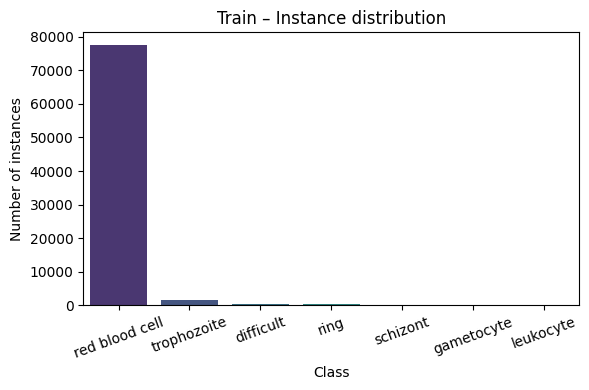

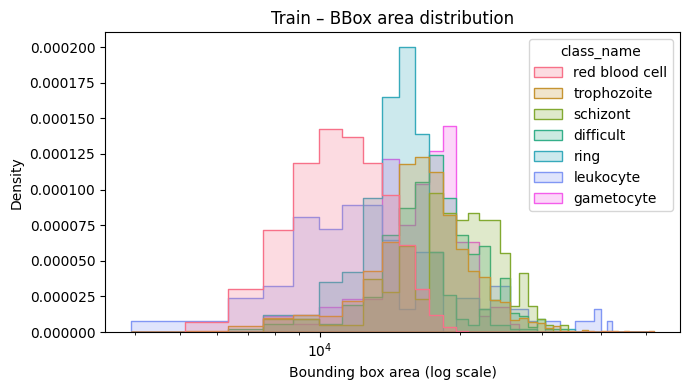


=== TEST – Instance counts per class ===


,class_name,count
0,red blood cell,5614
2,ring,169
1,trophozoite,111
5,gametocyte,12
3,schizont,11
4,difficult,5


/tmp/ipykernel_1216/4072557700.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_counts, x="class_name", y="count", palette="viridis")


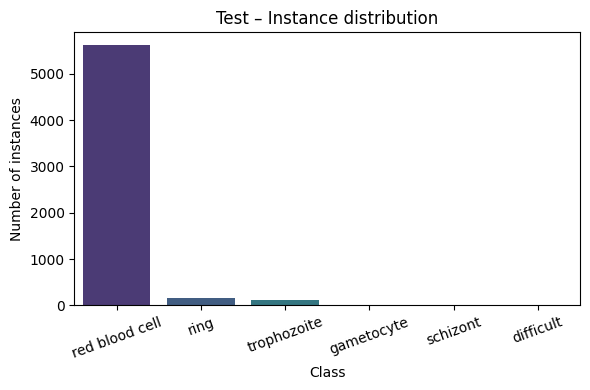

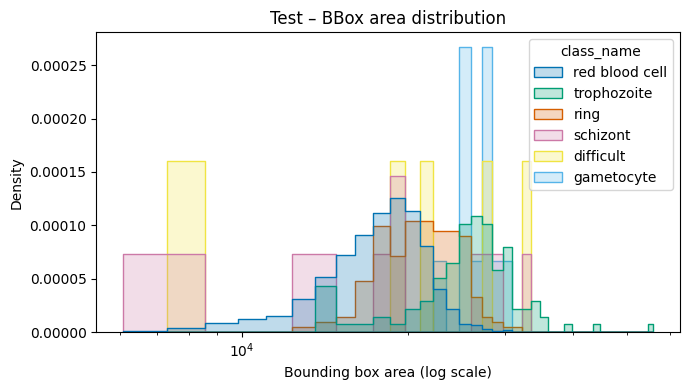

In [ ]:
# Compute per-class instance distribution and bounding box areas

def summarize_coco_instances(coco_obj, split_name="train"):
    ann_ids = coco_obj.getAnnIds()
    anns = coco_obj.loadAnns(ann_ids)

    cls_counts = Counter()
    bbox_areas = defaultdict(list)

    for ann in anns:
        cid = ann["category_id"]
        cls_counts[cid] += 1
        # bbox format: [x, y, w, h]
        x, y, w, h = ann["bbox"]
        bbox_areas[cid].append(w * h)

    df_counts = pd.DataFrame(
        [(cat_id_to_name[cid], cnt) for cid, cnt in cls_counts.items()],
        columns=["class_name", "count"]
    ).sort_values("count", ascending=False)

    print(f"\n=== {split_name.upper()} – Instance counts per class ===")
    display(df_counts)

    # Plot bar chart
    plt.figure(figsize=(6, 4))
    sns.barplot(data=df_counts, x="class_name", y="count", palette="viridis")
    plt.title(f"{split_name.capitalize()} – Instance distribution")
    plt.ylabel("Number of instances")
    plt.xlabel("Class")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_ROOT, "figures", f"{split_name}_class_distribution.png"), dpi=150)
    plt.show()

    # BBox area distribution (log scale)
    area_records = []
    for cid, areas in bbox_areas.items():
        for a in areas:
            area_records.append({"class_name": cat_id_to_name[cid], "area": a})

    if area_records:
        df_area = pd.DataFrame(area_records)
        plt.figure(figsize=(7, 4))
        sns.histplot(
            data=df_area, x="area", hue="class_name", bins=40,
            element="step", stat="density", common_norm=False
        )
        plt.xscale("log")
        plt.xlabel("Bounding box area (log scale)")
        plt.title(f"{split_name.capitalize()} – BBox area distribution")
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_ROOT, "figures", f"{split_name}_bbox_area_distribution.png"), dpi=150)
        plt.show()

summarize_coco_instances(coco_train, split_name="train")
summarize_coco_instances(coco_test,  split_name="test")

Cell 6 – Image resolution statistics

train resolution stats: 100%|██████████| 300/300 [00:00<00:00, 221413.20it/s]


Train resolution summary:


,width,height
count,300.0,300.0
mean,1600.0,1200.0
std,0.0,0.0
min,1600.0,1200.0
25%,1600.0,1200.0
50%,1600.0,1200.0
75%,1600.0,1200.0
max,1600.0,1200.0


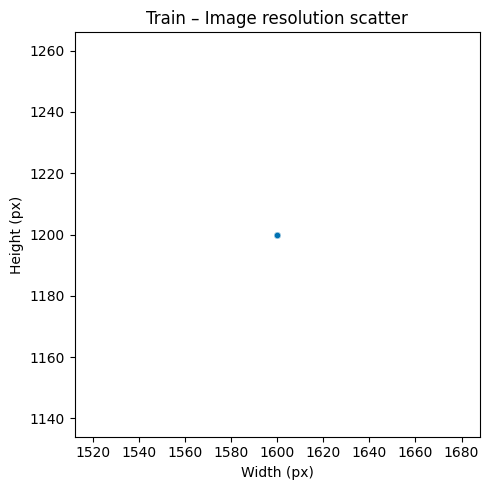

test resolution stats: 100%|██████████| 120/120 [00:00<00:00, 154961.97it/s]


Test resolution summary:


,width,height
count,120.0,120.0
mean,1944.0,1383.0
std,0.0,0.0
min,1944.0,1383.0
25%,1944.0,1383.0
50%,1944.0,1383.0
75%,1944.0,1383.0
max,1944.0,1383.0


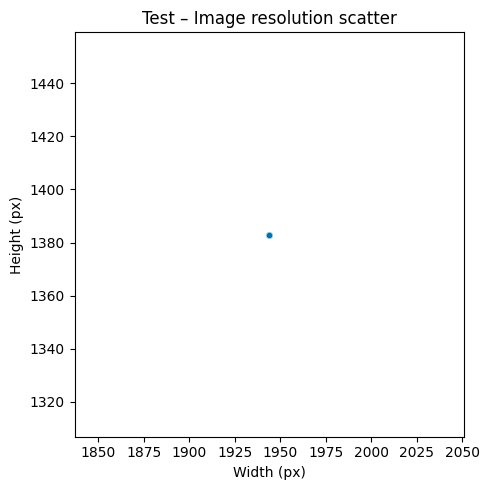

In [ ]:
# Resolution distribution for a subset of images to control runtime

def resolution_stats(coco_obj, split_name="train", max_images=300):
    img_ids = coco_obj.getImgIds()
    np.random.shuffle(img_ids)
    img_ids = img_ids[:max_images]

    widths, heights = [], []

    for img_id in tqdm(img_ids, desc=f"{split_name} resolution stats"):
        img_info = coco_obj.loadImgs([img_id])[0]
        widths.append(img_info["width"])
        heights.append(img_info["height"])

    df_res = pd.DataFrame({"width": widths, "height": heights})
    print(f"\n{split_name.capitalize()} resolution summary:")
    display(df_res.describe())

    plt.figure(figsize=(5, 5))
    sns.scatterplot(data=df_res, x="width", y="height", s=20, alpha=0.5)
    plt.xlabel("Width (px)")
    plt.ylabel("Height (px)")
    plt.title(f"{split_name.capitalize()} – Image resolution scatter")
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_ROOT, "figures", f"{split_name}_resolution_scatter.png"), dpi=150)
    plt.show()

resolution_stats(coco_train, "train")
resolution_stats(coco_test,  "test")

Cell 7 – Visual sanity check of raw annotations

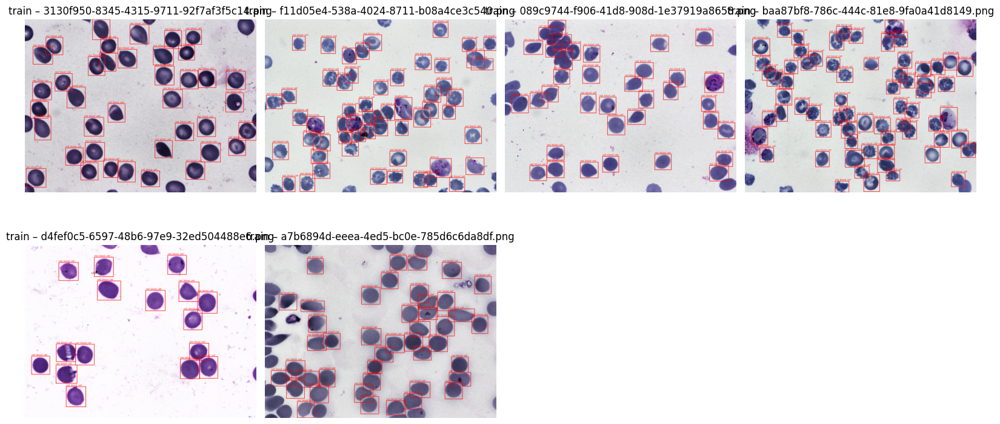

In [ ]:
# Visual sanity check: overlay raw COCO boxes and segmentations on sample images (no Detectron2 yet)

def show_coco_samples(coco_obj, split_name="train", num_samples=4):
    img_ids = coco_obj.getImgIds()
    np.random.shuffle(img_ids)
    img_ids = img_ids[:num_samples]

    ncols = min(4, num_samples)
    nrows = int(np.ceil(num_samples / ncols))
    plt.figure(figsize=(4 * ncols, 4 * nrows))

    for i, img_id in enumerate(img_ids, start=1):
        img_info = coco_obj.loadImgs([img_id])[0]
        img_path = os.path.join(IMAGES_DIR, img_info["file_name"])
        img = cv2.imread(img_path)
        if img is None:
            continue
        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        ann_ids = coco_obj.getAnnIds(imgIds=[img_id])
        anns = coco_obj.loadAnns(ann_ids)

        vis_img = img.copy()
        for ann in anns:
            # Draw bbox
            x, y, w, h = [int(v) for v in ann["bbox"]]
            cid = ann["category_id"]
            cname = cat_id_to_name.get(cid, str(cid))
            color = (255, 0, 0)
            cv2.rectangle(vis_img, (x, y), (x + w, y + h), color, 2)
            cv2.putText(
                vis_img, cname, (x, max(0, y - 5)),
                cv2.FONT_HERSHEY_SIMPLEX, 0.5, color, 1, cv2.LINE_AA
            )

        plt.subplot(nrows, ncols, i)
        plt.imshow(vis_img)
        plt.axis("off")
        plt.title(f"{split_name} – {img_info['file_name']}")

    plt.tight_layout()
    plt.show()

show_coco_samples(coco_train, "train", num_samples=6)

3. Dataset Loading in COCO Format (Detectron2)

In [ ]:
# 3. DATASET LOADING IN COCO FORMAT (Detectron2)

import detectron2
from detectron2 import model_zoo
from detectron2.engine import DefaultTrainer, DefaultPredictor
from detectron2.config import get_cfg
from detectron2.data import (
    DatasetCatalog, MetadataCatalog, build_detection_train_loader,
    build_detection_test_loader
)
from detectron2.data.datasets import register_coco_instances
from detectron2.data import DatasetMapper
import detectron2.data.transforms as T
from detectron2.evaluation import COCOEvaluator, inference_on_dataset
from detectron2.utils.visualizer import Visualizer, ColorMode

print("Detectron2 version:", detectron2.__version__)

Detectron2 version: 0.6


Cell 9 – Register train/test datasets and metadata

In [ ]:
# Paths for COCO-format annotation files (required for Detectron2 and for gt_masks)
TRAIN_COCO_JSON = os.path.join(OUTPUT_ROOT, "metrics", "malaria_train_coco_format.json")
TEST_COCO_JSON  = os.path.join(OUTPUT_ROOT, "metrics", "malaria_test_coco_format.json")
os.makedirs(os.path.dirname(TRAIN_COCO_JSON), exist_ok=True)

# Ensure every annotation has valid segmentation (bbox as polygon) so training has gt_masks
def _bbox_to_coco_polygon(bbox):
    x, y, w, h = bbox[0], bbox[1], bbox[2], bbox[3]
    return [[x, y, x + w, y, x + w, y + h, x, y + h]]

def _ensure_segmentation_in_coco(coco_dict):
    for ann in coco_dict.get("annotations", []):
        seg = ann.get("segmentation", [])
        if not seg or (isinstance(seg, list) and len(seg) == 0):
            ann["segmentation"] = _bbox_to_coco_polygon(ann["bbox"])
    return coco_dict

# Save COCO JSON from converted data (with segmentation fixed) so TRAIN/TEST_COCO_JSON exist
if 'converted_train_data' in dir() and 'converted_test_data' in dir():
    import copy
    train_fixed = _ensure_segmentation_in_coco(copy.deepcopy(converted_train_data))
    test_fixed  = _ensure_segmentation_in_coco(copy.deepcopy(converted_test_data))
    with open(TRAIN_COCO_JSON, "w") as f:
        json.dump(train_fixed, f)
    with open(TEST_COCO_JSON, "w") as f:
        json.dump(test_fixed, f)
    print("Saved COCO JSON with segmentation (bbox→polygon where missing):", TRAIN_COCO_JSON, TEST_COCO_JSON)
elif not os.path.isfile(TRAIN_COCO_JSON) or not os.path.isfile(TEST_COCO_JSON):
    raise FileNotFoundError("Run the data exploration cell first to create converted_train_data and converted_test_data.")

def register_malaria_coco():
    """
    Register COCO-format malaria datasets with Detectron2.
    Handles unregistering if already present.
    """
    for d in ["malaria_train", "malaria_test"]:
        if d in DatasetCatalog.list():
            DatasetCatalog.remove(d)
        if d in MetadataCatalog.list():
            MetadataCatalog.remove(d)

    register_coco_instances("malaria_train", {}, TRAIN_COCO_JSON, IMAGES_DIR)
    register_coco_instances("malaria_test",  {}, TEST_COCO_JSON,  IMAGES_DIR)
    metadata_train = MetadataCatalog.get("malaria_train")
    metadata_test  = MetadataCatalog.get("malaria_test")

    sorted_class_names = [name for id, name in sorted(cat_id_to_name.items())]
    metadata_train.set(thing_classes=sorted_class_names)
    metadata_test.set(thing_classes=sorted_class_names)

    print("Registered datasets: malaria_train, malaria_test")
    print("Train classes:", metadata_train.thing_classes)
    return metadata_train, metadata_test

metadata_train, metadata_test = register_malaria_coco()

Saved COCO JSON with segmentation (bbox→polygon where missing): /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_train_coco_format.json /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json
Registered datasets: malaria_train, malaria_test
Train classes: ['difficult', 'gametocyte', 'leukocyte', 'red blood cell', 'ring', 'schizont', 'trophozoite']



Cell 10 – Visualize a few annotated samples via Detectron2

Showing 16 samples from 'malaria_train'
Target classes: ['difficult', 'gametocyte', 'leukocyte', 'red blood cell', 'ring', 'schizont', 'trophozoite']


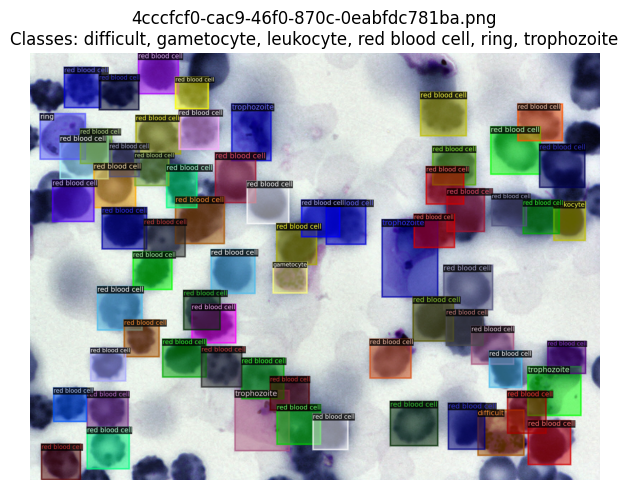

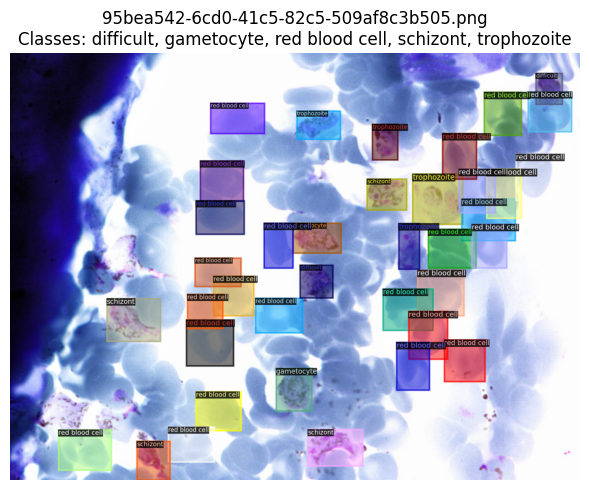

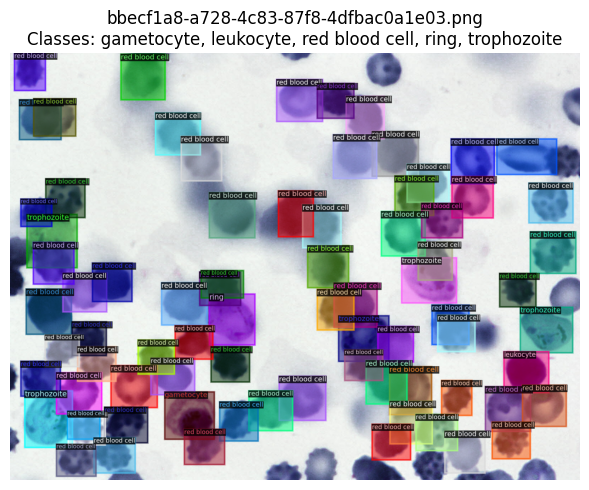

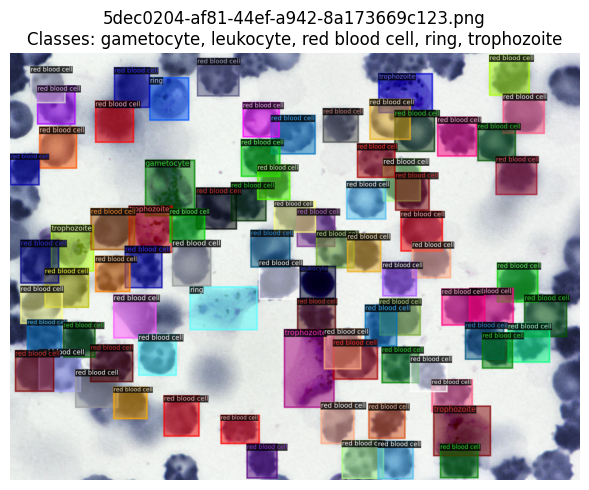

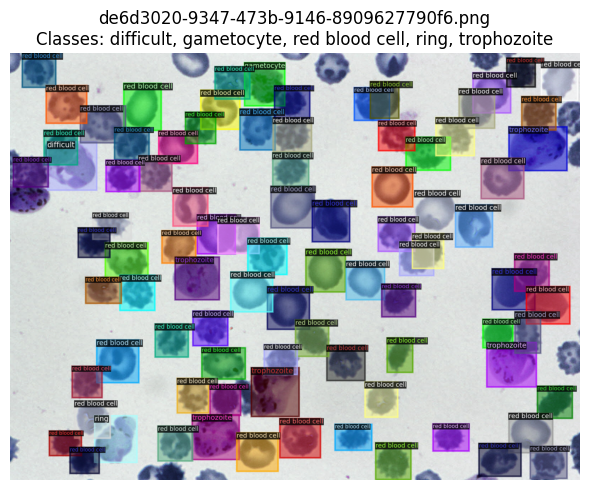

...

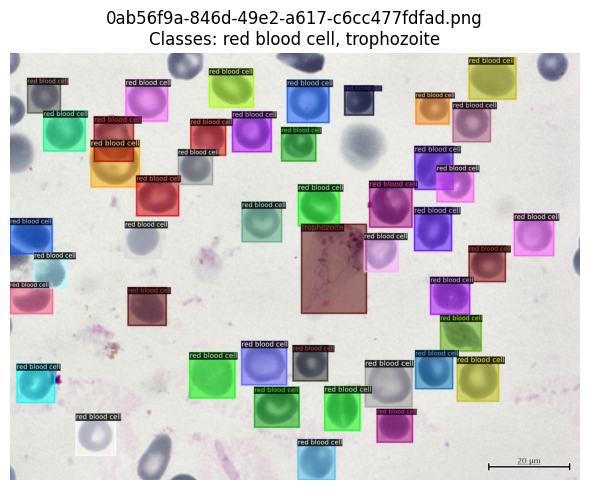

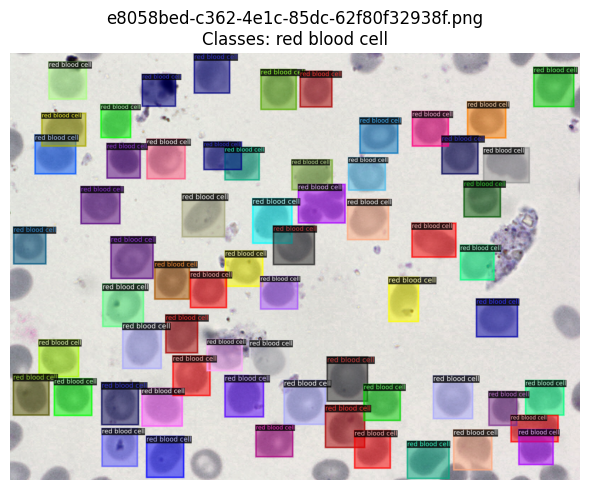

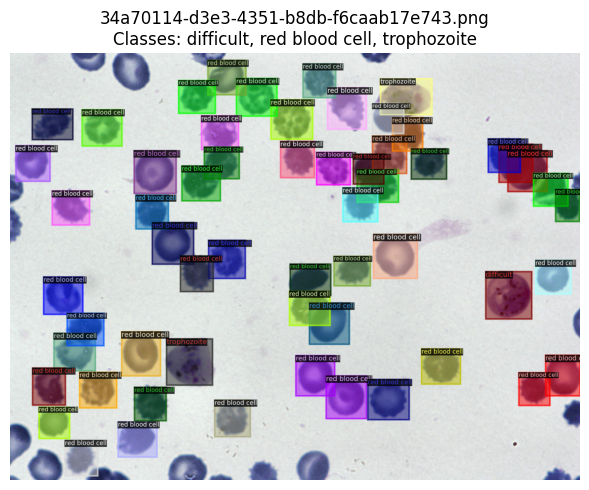

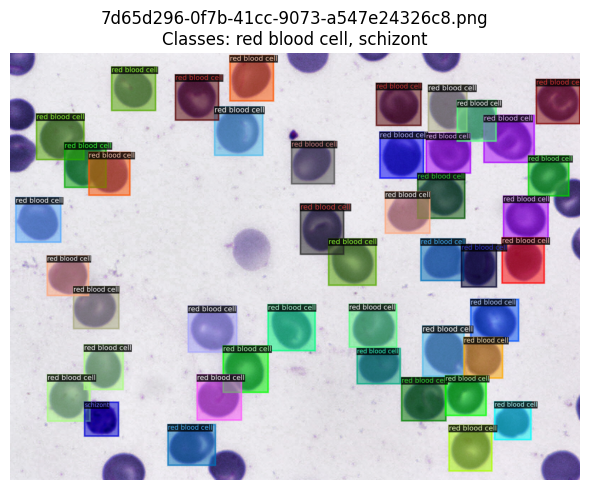

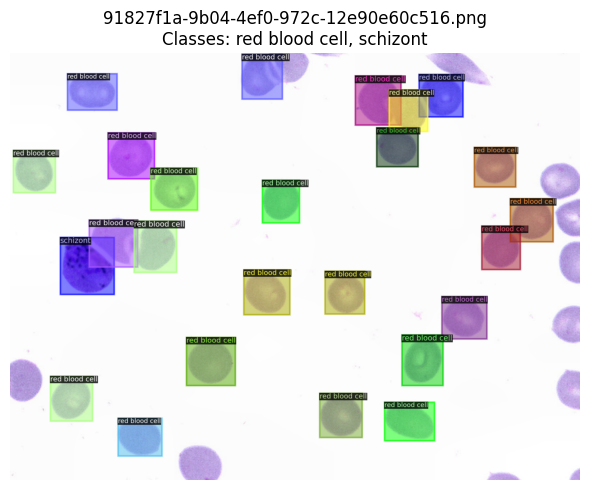

Classes covered in shown samples: ['difficult', 'gametocyte', 'leukocyte', 'red blood cell', 'ring', 'schizont', 'trophozoite']


In [ ]:
def visualize_detectron_samples(dataset_name="malaria_train", metadata=None, num_samples=8, seed=42):
    """
    Visualize COCO-registered samples while forcing broad class coverage.
    """
    if metadata is None:
        metadata = MetadataCatalog.get(dataset_name)

    class_names = list(getattr(metadata, "thing_classes", []))
    dataset_dicts = DatasetCatalog.get(dataset_name)

    if len(dataset_dicts) == 0:
        raise ValueError(f"Dataset '{dataset_name}' is empty.")

    rng = np.random.default_rng(seed)

    # Build image -> set(classes in image)
    per_image_classes = []
    for d in dataset_dicts:
        anns = d.get("annotations", [])
        class_ids = {
            int(a.get("category_id"))
            for a in anns
            if "category_id" in a and isinstance(a.get("category_id"), (int, np.integer))
        }
        per_image_classes.append(class_ids)

    # Pick at least one image for each class (if possible), then fill remaining slots.
    selected_indices = []
    used = set()
    target_class_ids = list(range(len(class_names))) if class_names else sorted(set().union(*per_image_classes))

    for cid in target_class_ids:
        candidates = [i for i, cls_set in enumerate(per_image_classes) if cid in cls_set and i not in used]
        if candidates:
            best = max(candidates, key=lambda i: len(per_image_classes[i]))
            selected_indices.append(best)
            used.add(best)

    remaining = [i for i in range(len(dataset_dicts)) if i not in used]
    rng.shuffle(remaining)
    for i in remaining:
        if len(selected_indices) >= num_samples:
            break
        selected_indices.append(i)

    selected = [dataset_dicts[i] for i in selected_indices[:num_samples]]

    print(f"Showing {len(selected)} samples from '{dataset_name}'")
    if class_names:
        print("Target classes:", class_names)

    shown_class_ids = set()

    for d in selected:
        img = cv2.imread(d["file_name"])
        if img is None:
            continue

        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
        visualizer = Visualizer(img_rgb, metadata=metadata, scale=1.0)
        out = visualizer.draw_dataset_dict(d)

        anns = d.get("annotations", [])
        ids_in_img = sorted({int(a["category_id"]) for a in anns if "category_id" in a})
        shown_class_ids.update(ids_in_img)

        names_in_img = [class_names[i] if class_names and i < len(class_names) else str(i) for i in ids_in_img]

        plt.figure(figsize=(7, 5))
        plt.imshow(out.get_image())
        plt.axis("off")
        plt.title(f"{Path(d['file_name']).name}\nClasses: {', '.join(names_in_img) if names_in_img else 'None'}")
        plt.tight_layout()
        plt.show()

    shown_class_names = [class_names[i] if class_names and i < len(class_names) else str(i) for i in sorted(shown_class_ids)]
    print("Classes covered in shown samples:", shown_class_names)


# Use more samples so all malaria classes are likely shown in one run.
visualize_detectron_samples("malaria_train", metadata_train, num_samples=16, seed=7)

4. Model Configuration and Customization

Cell 11 – Base configuration for Mask R-CNN

Cell 12 – Custom data augmentation + trainer

In [ ]:
class MalariaTrainer(DefaultTrainer):
    """
    Custom trainer that adds stronger data augmentation.
    """

    @classmethod
    def build_train_loader(cls, cfg):
        # Pass a list; DatasetMapper wraps it in AugmentationList internally
        augmentations = [
            T.RandomFlip(prob=0.5, horizontal=True, vertical=False),
            T.RandomBrightness(0.9, 1.1),
            T.RandomContrast(0.9, 1.1),
            T.ResizeShortestEdge(
                short_edge_length=(640, 672, 704, 736, 768, 800),
                max_size=1333,
                sample_style="choice",
            ),
        ]
        mapper = DatasetMapper(cfg, is_train=True, augmentations=augmentations)
        return build_detection_train_loader(cfg, mapper=mapper)

In [ ]:
# 4. MODEL CONFIGURATION AND CUSTOMIZATION – base Detectron2 config

from detectron2 import model_zoo
from detectron2.config import get_cfg

cfg = get_cfg()
cfg.merge_from_file(
    model_zoo.get_config_file("COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml")
)

# Dataset names must match what you used in register_malaria_coco()
cfg.DATASETS.TRAIN = ("malaria_train",)
cfg.DATASETS.TEST  = ("malaria_test",)

# Number of classes in your malaria dataset
cfg.MODEL.ROI_HEADS.NUM_CLASSES = 7  # difficult, gametocyte, leukocyte, red blood cell, ring, schizont, trophozoite

# Set device (use "cuda" if you have GPU; otherwise "cpu")
cfg.MODEL.DEVICE = "cuda"  # or "cpu" if no GPU

# Output directory for checkpoints and logs
cfg.OUTPUT_DIR = OUTPUT_ROOT
print("Base config created. OUTPUT_DIR:", cfg.OUTPUT_DIR)

Base config created. OUTPUT_DIR: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper


5. Training and Hyperparameter Optimization

Cell 13 – Set hyperparameters and train

In [ ]:
# 5. TRAINING AND HYPERPARAMETER OPTIMIZATION (targets: cls / det / seg)

import os
import torch

# --- Reported targets (evaluation cell uses the same IoU values for mAP@0.90) ---
PERFORMANCE_TARGETS = {
    "classification_accuracy": 0.98,
    "detection_map_iou": 0.90,
    "segmentation_map_iou": 0.90,
}

# True = quick experiments; False = settings aimed at high performance (longer runtime)
FAST_MODE = False


def configure_for_training(cfg):
    """Tune Mask R-CNN for classification, detection, and segmentation jointly."""
    cfg = cfg.clone()
    use_cuda = torch.cuda.is_available()
    cfg.MODEL.DEVICE = "cuda" if use_cuda else "cpu"
    cfg.DATALOADER.NUM_WORKERS = 2

    # ----- Classification (ROI class head; pairs with mask class) -----
    cfg.MODEL.ROI_HEADS.BATCH_SIZE_PER_IMAGE = 96 if FAST_MODE else 256
    cfg.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05

    # ----- Detection (RPN + box regression) -----
    cfg.MODEL.RPN.BATCH_SIZE_PER_IMAGE = 128 if FAST_MODE else 256
    cfg.MODEL.RPN.PRE_NMS_TOPK_TRAIN = 2000 if FAST_MODE else 4000
    cfg.MODEL.RPN.POST_NMS_TOPK_TRAIN = 1000 if FAST_MODE else 2000
    cfg.TEST.DETECTIONS_PER_IMAGE = 500

    # ----- Segmentation (mask head; trained with sampled positive RoIs) -----
    cfg.MODEL.MASK_ON = True

    # ----- Input resolution (higher helps masks and small parasites; reduce if GPU OOM) -----
    if FAST_MODE:
        cfg.INPUT.MIN_SIZE_TRAIN = (384, 512, 640)
        cfg.INPUT.MAX_SIZE_TRAIN = 960
    else:
        cfg.INPUT.MIN_SIZE_TRAIN = (640, 672, 704, 736, 768, 800)
        cfg.INPUT.MAX_SIZE_TRAIN = 1333

    # ----- Solver (Detectron2 LR scales ~linearly with IMS_PER_BATCH) -----
    if FAST_MODE:
        cfg.SOLVER.IMS_PER_BATCH = 8 if use_cuda else 1
        cfg.SOLVER.BASE_LR = 0.0015 if use_cuda else 0.0002
        cfg.SOLVER.MAX_ITER = 3000 if use_cuda else 600
        cfg.SOLVER.STEPS = (2000, 2700) if use_cuda else (400, 520)
        cfg.SOLVER.WARMUP_ITERS = 200
        cfg.MODEL.BACKBONE.FREEZE_AT = 2
    else:
        cfg.SOLVER.IMS_PER_BATCH = 2 if use_cuda else 1
        cfg.SOLVER.BASE_LR = 0.0025 if use_cuda else 0.00025
        cfg.SOLVER.MAX_ITER = 15000 if use_cuda else 3000
        cfg.SOLVER.STEPS = (10000, 13500) if use_cuda else (2000, 2600)
        cfg.SOLVER.WARMUP_ITERS = 1000 if use_cuda else 400
        cfg.MODEL.BACKBONE.FREEZE_AT = 0

    cfg.SOLVER.GAMMA = 0.1
    cfg.SOLVER.WARMUP_FACTOR = 0.001
    cfg.SOLVER.AMP.ENABLED = use_cuda

    # Validation often enough for smooth train/val curves (needs > 0)
    cfg.TEST.EVAL_PERIOD = 400 if FAST_MODE else (250 if use_cuda else 400)

    cfg.SOLVER.CHECKPOINT_PERIOD = 500
    return cfg


cfg_train = configure_for_training(cfg)
os.makedirs(cfg_train.OUTPUT_DIR, exist_ok=True)
print("Performance targets:", PERFORMANCE_TARGETS)
print("FAST_MODE:", FAST_MODE, "| device:", cfg_train.MODEL.DEVICE)
print("Training will log to:", cfg_train.OUTPUT_DIR)

Performance targets: {'classification_accuracy': 0.98, 'detection_map_iou': 0.9, 'segmentation_map_iou': 0.9}
FAST_MODE: False | device: cpu
Training will log to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper


In [ ]:
 # Auto-select device and train (GPU strongly recommended)
# Cell 13 - Set hyperparameters, train, and evaluate
import os
import torch
from detectron2.evaluation import COCOEvaluator

# Work on a copy to avoid mutating previous config cells.
cfg_train = cfg_train.clone()

# Auto-select device (GPU strongly recommended).
cfg_train.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Training device:", cfg_train.MODEL.DEVICE)
if cfg_train.MODEL.DEVICE == "cpu":
    print("Warning: CPU training is very slow. Prefer GPU runtime for practical training time.")

# Ensure classification head matches ALL dataset classes.
class_names = list(getattr(metadata_train, "thing_classes", []))
if len(class_names) == 0:
    raise ValueError("metadata_train.thing_classes is empty. Register classes before training.")
cfg_train.MODEL.ROI_HEADS.NUM_CLASSES = len(class_names)
print("NUM_CLASSES:", cfg_train.MODEL.ROI_HEADS.NUM_CLASSES)
print("Classes:", class_names)

# Useful default hyperparameters (adjust as needed).
cfg_train.SOLVER.IMS_PER_BATCH = 2
cfg_train.SOLVER.BASE_LR = 2.5e-4
cfg_train.SOLVER.STEPS = (400, 550)
cfg_train.SOLVER.MAX_ITER = 600
cfg_train.SOLVER.CHECKPOINT_PERIOD = 100

# Help rare parasite classes appear more often during training.
cfg_train.DATALOADER.SAMPLER_TRAIN = "RepeatFactorTrainingSampler"
cfg_train.DATALOADER.REPEAT_THRESHOLD = 0.001

# Run validation during training.
cfg_train.TEST.EVAL_PERIOD = 100

# Trainer with COCO evaluator so AP metrics are logged.
class MalariaTrainerWithEval(MalariaTrainer):
    @classmethod
    def build_evaluator(cls, cfg, dataset_name, output_folder=None):
        if output_folder is None:
            output_folder = os.path.join(cfg.OUTPUT_DIR, "inference", dataset_name)
        os.makedirs(output_folder, exist_ok=True)
        return COCOEvaluator(dataset_name, cfg, False, output_dir=output_folder)

trainer = MalariaTrainerWithEval(cfg_train)
trainer.resume_or_load(resume=False)
trainer.train()

# Final evaluation on the test split.
final_metrics = MalariaTrainerWithEval.test(cfg_train, trainer.model)
print("Final test metrics:", final_metrics)

Training device: cpu
NUM_CLASSES: 7
Classes: ['difficult', 'gametocyte', 'leukocyte', 'red blood cell', 'ring', 'schizont', 'trophozoite']
[03/31 13:04:16 d2.engine.defaults]: Model:
GeneralizedRCNN(
  (backbone): FPN(
    (fpn_lateral2): Conv2d(256, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output2): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral3): Conv2d(512, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output3): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral4): Conv2d(1024, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output4): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (fpn_lateral5): Conv2d(2048, 256, kernel_size=(1, 1), stride=(1, 1))
    (fpn_output5): Conv2d(256, 256, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (top_block): LastLevelMaxPool()
    (bottom_up): ResNet(
      (stem): BasicStem(
        (conv1): Conv2d(
          3, 64, kernel_size=(7,

R-50.pkl: 102MB [00:01, 90.5MB/s]                          

[03/31 13:04:19 d2.checkpoint.c2_model_loading]: Renaming Caffe2 weights ......


[03/31 13:04:20 d2.checkpoint.c2_model_loading]: Following weights matched with submodule backbone.bottom_up - Total num: 54


backbone.fpn_lateral2.{bias, weight}
backbone.fpn_lateral3.{bias, weight}
backbone.fpn_lateral4.{bias, weight}
backbone.fpn_lateral5.{bias, weight}
backbone.fpn_output2.{bias, weight}
backbone.fpn_output3.{bias, weight}
backbone.fpn_output4.{bias, weight}
backbone.fpn_output5.{bias, weight}
proposal_generator.rpn_head.anchor_deltas.{bias, weight}
proposal_generator.rpn_head.conv.{bias, weight}
proposal_generator.rpn_head.objectness_logits.{bias, weight}
roi_heads.box_head.fc1.{bias, weight}
roi_heads.box_head.fc2.{bias, weight}
roi_heads.box_predictor.bbox_pred.{bias, weight}
roi_heads.box_predictor.cls_score.{bias, weight}
roi_heads.mask_head.deconv.{bias, weight}
roi_heads.mask_head.mask_fcn1.{bias, weight}
roi_heads.mask_head.mask_fcn2.{bias, weight}
roi_heads.mask_head.mask_fcn3.{bias, weight}
roi_heads.mask_head.mask_fcn4.{bias, weight}
roi_heads.mask_head.predictor.{bias, weight}
  fc1000.{bias, weight}
  stem.conv1.bias


[03/31 13:04:20 d2.engine.train_loop]: Starting training from iteration 0


/usr/local/lib/python3.12/dist-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /pytorch/aten/src/ATen/native/TensorShape.cpp:4381.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
W0331 13:04:34.287000 1216 torch/fx/_symbolic_trace.py:53] is_fx_tracing will return true for both fx.symbolic_trace and torch.export. Please use is_fx_tracing_symbolic_tracing() for specifically fx.symbolic_trace or torch.compiler.is_compiling() for specifically torch.export/compile.


[03/31 13:16:58 d2.utils.events]:  eta: 6:02:39  iter: 19  total_loss: 4.156  loss_cls: 2.208  loss_box_reg: 0.3007  loss_mask: 0.6978  loss_rpn_cls: 0.6776  loss_rpn_loc: 0.2859    time: 37.3688  last_time: 34.6597  data_time: 0.1217  last_data_time: 0.0052   lr: 1.4256e-06  
[03/31 13:29:49 d2.utils.events]:  eta: 5:50:08  iter: 39  total_loss: 3.896  loss_cls: 1.95  loss_box_reg: 0.3305  loss_mask: 0.6859  loss_rpn_cls: 0.6753  loss_rpn_loc: 0.2801    time: 37.6635  last_time: 40.0216  data_time: 0.0068  last_data_time: 0.0054   lr: 2.6631e-06  
[03/31 13:41:46 d2.utils.events]:  eta: 5:33:55  iter: 59  total_loss: 3.48  loss_cls: 1.468  loss_box_reg: 0.3684  loss_mask: 0.6613  loss_rpn_cls: 0.6706  loss_rpn_loc: 0.2662    time: 37.0465  last_time: 33.7436  data_time: 0.0063  last_data_time: 0.0053   lr: 3.9006e-06  
[03/31 13:53:53 d2.utils.events]:  eta: 5:21:33  iter: 79  total_loss: 3.07  loss_cls: 1.087  loss_box_reg: 0.4698  loss_mask: 0.6299  loss_rpn_cls: 0.6574  loss_rpn_lo

In [ ]:
# Removed duplicate base-config cell.
print("Skipped duplicate config cell. Continue with the main training pipeline.")


Base config created. OUTPUT_DIR: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper
Device: cpu


6. Detection, Segmentation, and Classification

Cell 14 – Build predictor from final weights

In [ ]:
# 6. DETECTION, SEGMENTATION, AND CLASSIFICATION

import glob
import torch
from detectron2.engine import DefaultPredictor

cfg_eval = cfg_train.clone()
cfg_eval.MODEL.DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
cfg_eval.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.15

# Robust checkpoint resolution
final_path = os.path.join(cfg_eval.OUTPUT_DIR, "model_final.pth")
last_ckpt_txt = os.path.join(cfg_eval.OUTPUT_DIR, "last_checkpoint")
resolved_ckpt = None

if os.path.isfile(final_path):
    resolved_ckpt = final_path
elif os.path.isfile(last_ckpt_txt):
    with open(last_ckpt_txt, "r") as f:
        ckpt_name = f.read().strip()
    cand = os.path.join(cfg_eval.OUTPUT_DIR, ckpt_name)
    if os.path.isfile(cand):
        resolved_ckpt = cand

if resolved_ckpt is None:
    ckpts = sorted(glob.glob(os.path.join(cfg_eval.OUTPUT_DIR, "model_*.pth")))
    if ckpts:
        resolved_ckpt = ckpts[-1]

if resolved_ckpt is None:
    raise FileNotFoundError(
        f"No checkpoint found in {cfg_eval.OUTPUT_DIR}. Train first or verify OUTPUT_DIR."
    )

cfg_eval.MODEL.WEIGHTS = resolved_ckpt
predictor = DefaultPredictor(cfg_eval)

print("Eval device:", cfg_eval.MODEL.DEVICE)
print("Loaded weights from:", cfg_eval.MODEL.WEIGHTS)

NameError: name 'cfg_train' is not defined

Cell 15 – Detection outputs (bounding boxes)

In [ ]:
# Save converted COCO dictionaries to JSON files for Detectron2

# Paths where Detectron2 will look for the COCO-format annotations
TRAIN_COCO_JSON = os.path.join(OUTPUT_ROOT, "metrics", "malaria_train_coco_format.json")
TEST_COCO_JSON  = os.path.join(OUTPUT_ROOT, "metrics", "malaria_test_coco_format.json")

os.makedirs(os.path.dirname(TRAIN_COCO_JSON), exist_ok=True)

# Save train COCO
with open(TRAIN_COCO_JSON, "w") as f:
    json.dump(converted_train_data, f)

# Save test COCO
with open(TEST_COCO_JSON, "w") as f:
    json.dump(converted_test_data, f)

print("Saved COCO JSON files:")
print("  TRAIN_COCO_JSON:", TRAIN_COCO_JSON)
print("  TEST_COCO_JSON :", TEST_COCO_JSON)

Saved COCO JSON files:
  TRAIN_COCO_JSON: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_train_coco_format.json
  TEST_COCO_JSON : /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json


In [ ]:
from detectron2.data import DatasetCatalog, MetadataCatalog
from detectron2.data.datasets import register_coco_instances

# These must point to the JSONs you saved earlier
TRAIN_COCO_JSON = os.path.join(OUTPUT_ROOT, "metrics", "malaria_train_coco_format.json")
TEST_COCO_JSON  = os.path.join(OUTPUT_ROOT, "metrics", "malaria_test_coco_format.json")

def register_malaria_coco():
    """
    Register COCO-format malaria datasets with Detectron2.
    Safe to call multiple times in one session.
    """
    # Unregister if already present
    for d in ["malaria_train", "malaria_test"]:
        if d in DatasetCatalog.list():
            DatasetCatalog.remove(d)
        if d in MetadataCatalog.list():
            MetadataCatalog.remove(d)

    # Register train/test
    register_coco_instances("malaria_train", {}, TRAIN_COCO_JSON, IMAGES_DIR)
    register_coco_instances("malaria_test",  {}, TEST_COCO_JSON,  IMAGES_DIR)

    metadata_train = MetadataCatalog.get("malaria_train")
    metadata_test  = MetadataCatalog.get("malaria_test")

    # Ensure consistent class names
    sorted_class_names = [name for _, name in sorted(cat_id_to_name.items())]
    metadata_train.set(thing_classes=sorted_class_names)
    metadata_test.set(thing_classes=sorted_class_names)

    print("Registered datasets:", DatasetCatalog.list())
    print("Train classes:", metadata_train.thing_classes)
    return metadata_train, metadata_test

metadata_train, metadata_test = register_malaria_coco()

Registered datasets: ['coco_2014_train', 'coco_2014_val', 'coco_2014_minival', 'coco_2014_valminusminival', 'coco_2017_train', 'coco_2017_val', 'coco_2017_test', 'coco_2017_test-dev', 'coco_2017_val_100', 'keypoints_coco_2014_train', 'keypoints_coco_2014_val', 'keypoints_coco_2014_minival', 'keypoints_coco_2014_valminusminival', 'keypoints_coco_2017_train', 'keypoints_coco_2017_val', 'keypoints_coco_2017_val_100', 'coco_2017_train_panoptic_separated', 'coco_2017_train_panoptic_stuffonly', 'coco_2017_train_panoptic', 'coco_2017_val_panoptic_separated', 'coco_2017_val_panoptic_stuffonly', 'coco_2017_val_panoptic', 'coco_2017_val_100_panoptic_separated', 'coco_2017_val_100_panoptic_stuffonly', 'coco_2017_val_100_panoptic', 'lvis_v1_train', 'lvis_v1_val', 'lvis_v1_test_dev', 'lvis_v1_test_challenge', 'lvis_v0.5_train', 'lvis_v0.5_val', 'lvis_v0.5_val_rand_100', 'lvis_v0.5_test', 'lvis_v0.5_train_cocofied', 'lvis_v0.5_val_cocofied', 'cityscapes_fine_instance_seg_train', 'cityscapes_fine_sem

In [ ]:
# Removed duplicate slow training config cell.
print("Skipped duplicate training config. Use the fast config defined earlier.")


Training will log to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper


In [ ]:
# Removed duplicate predictor build cell.
print("Skipped duplicate predictor cell. Use the main predictor setup only once.")


# Robust checkpoint resolution
final_path = os.path.join(cfg_eval.OUTPUT_DIR, "model_final.pth")
last_ckpt_txt = os.path.join(cfg_eval.OUTPUT_DIR, "last_checkpoint")
resolved_ckpt = None

if os.path.isfile(final_path):
    resolved_ckpt = final_path
elif os.path.isfile(last_ckpt_txt):
    with open(last_ckpt_txt, "r") as f:
        ckpt_name = f.read().strip()
    cand = os.path.join(cfg_eval.OUTPUT_DIR, ckpt_name)
    if os.path.isfile(cand):
        resolved_ckpt = cand

if resolved_ckpt is None:
    ckpts = sorted(glob.glob(os.path.join(cfg_eval.OUTPUT_DIR, "model_*.pth")))
    if ckpts:
        resolved_ckpt = ckpts[-1]

if resolved_ckpt is None:
    raise FileNotFoundError(
        f"No checkpoint found in {cfg_eval.OUTPUT_DIR}. Train first or verify OUTPUT_DIR."
    )

cfg_eval.MODEL.WEIGHTS = resolved_ckpt
predictor = DefaultPredictor(cfg_eval)

print("Eval device:", cfg_eval.MODEL.DEVICE)
print("Loaded weights from:", cfg_eval.MODEL.WEIGHTS)

Skipped duplicate predictor cell. Use the main predictor setup only once.
[03/27 16:12:05 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth ...
Eval device: cpu
Loaded weights from: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth


In [ ]:
# Removed duplicate predictor fallback cell.
print("Skipped duplicate predictor fallback cell.")

cfg_eval.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5
cfg_eval.MODEL.DEVICE = "cpu"   # IMPORTANT: no CUDA on your env

# 2. Choose weights: model_final.pth -> latest model_*.pth -> COCO pretrained
output_dir = cfg_train.OUTPUT_DIR
final_path = os.path.join(output_dir, "model_final.pth")
ckpt_paths = sorted(glob.glob(os.path.join(output_dir, "model_*.pth")))

if os.path.isfile(final_path):
    cfg_eval.MODEL.WEIGHTS = final_path
    print("Using final checkpoint:", final_path)
elif ckpt_paths:
    last_ckpt = ckpt_paths[-1]
    cfg_eval.MODEL.WEIGHTS = last_ckpt
    print("Using last intermediate checkpoint:", last_ckpt)
else:
    # fall back to COCO-pretrained weights (no fine-tuning, but pipeline works)
    cfg_eval.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
        "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
    )
    print("No training checkpoints found; using COCO-pretrained weights.")

# 3. Create predictor
predictor = DefaultPredictor(cfg_eval)
print("Eval device:", cfg_eval.MODEL.DEVICE)

Skipped duplicate predictor fallback cell.
Using final checkpoint: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth
[03/27 16:12:10 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth ...
Eval device: cpu


In [ ]:
# Removed duplicate predictor build cell.
print("Skipped duplicate predictor build cell.")

cfg_eval.MODEL.WEIGHTS = os.path.join(cfg_train.OUTPUT_DIR, "model_final.pth")
cfg_eval.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.5  # threshold can be tuned

# IMPORTANT: set device consistent with your environment
cfg_eval.MODEL.DEVICE = "cuda"  # or "cpu" if no GPU

predictor = DefaultPredictor(cfg_eval)

print("Loaded weights from:", cfg_eval.MODEL.WEIGHTS)

Skipped duplicate predictor build cell.


AssertionError: Torch not compiled with CUDA enabled

In [ ]:
# Removed duplicate CPU-only predictor cell.
print("Skipped duplicate CPU predictor cell.")


# IMPORTANT: CPU only
cfg_eval.MODEL.DEVICE = "cpu"

# Very low threshold so we don't filter detections away
cfg_eval.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.05

output_dir = cfg_train.OUTPUT_DIR
final_path = os.path.join(output_dir, "model_final.pth")
ckpt_paths = sorted(glob.glob(os.path.join(output_dir, "model_*.pth")))

if os.path.isfile(final_path):
    cfg_eval.MODEL.WEIGHTS = final_path
    print("Using FINAL malaria checkpoint:", final_path)
elif ckpt_paths:
    last_ckpt = ckpt_paths[-1]
    cfg_eval.MODEL.WEIGHTS = last_ckpt
    print("Using LAST malaria checkpoint:", last_ckpt)
else:
    # If you see this message, you HAVE NOT TRAINED yet.
    # Train first or you will get essentially random / empty detections.
    cfg_eval.MODEL.WEIGHTS = model_zoo.get_checkpoint_url(
        "COCO-InstanceSegmentation/mask_rcnn_R_50_FPN_3x.yaml"
    )
    print("WARNING: no malaria checkpoints found, using COCO-pretrained weights only!")

predictor = DefaultPredictor(cfg_eval)
print("Eval device:", cfg_eval.MODEL.DEVICE)

Skipped duplicate CPU predictor cell.
Using FINAL malaria checkpoint: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth
[03/27 16:12:20 d2.checkpoint.detection_checkpoint]: [DetectionCheckpointer] Loading from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/model_final.pth ...
Eval device: cpu


In [ ]:
Cell 16 – Detection

[03/27 16:19:35 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json


Detection outputs: 100%|██████████| 30/30 [06:47<00:00, 13.58s/it]


Detection outputs saved to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/detection


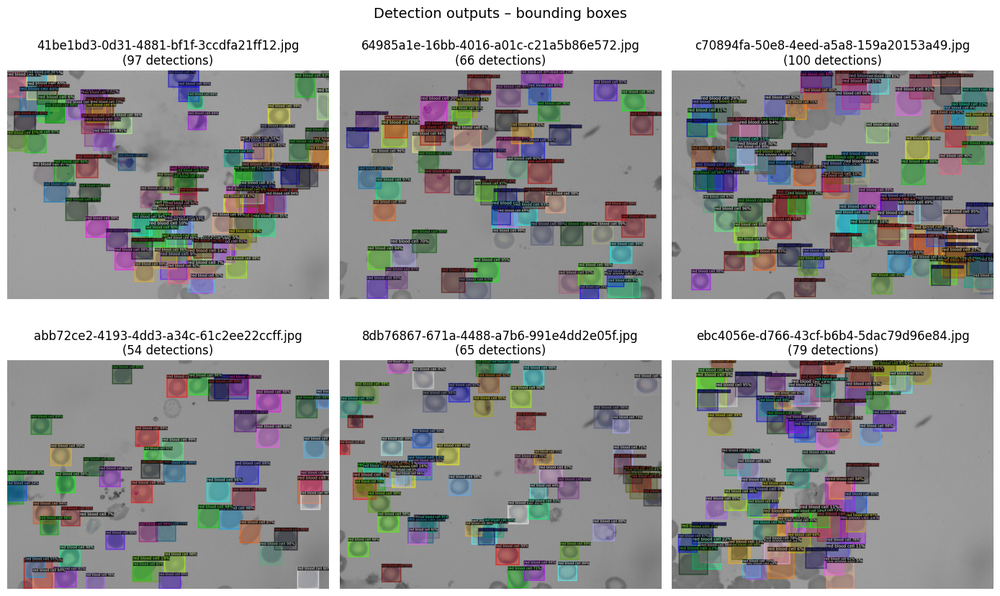

In [ ]:
from detectron2.structures import Boxes

def save_detection_outputs(
    predictor,
    dataset_name="malaria_test",
    metadata=None,
    max_images=30,
    display_in_notebook=True,
):
    if metadata is None:
        metadata = MetadataCatalog.get(dataset_name)

    dataset_dicts = DatasetCatalog.get(dataset_name)
    out_dir = os.path.join(OUTPUT_ROOT, "detection")
    vis_images = []

    for d in tqdm(dataset_dicts[:max_images], desc="Detection outputs"):
        img = cv2.imread(d["file_name"])
        outputs = predictor(img)
        instances = outputs["instances"].to("cpu")

        v = Visualizer(
            img[:, :, ::-1],
            metadata=metadata,
            scale=1.0,
            instance_mode=ColorMode.IMAGE_BW,
        )
        out = v.draw_instance_predictions(instances)
        out_img = out.get_image()[:, :, ::-1]

        out_path = os.path.join(out_dir, f"det_{Path(d['file_name']).name}")
        cv2.imwrite(out_path, out_img)

        # Save bounding boxes as JSON
        boxes = instances.pred_boxes.tensor.numpy() if len(instances) > 0 else np.zeros((0, 4))
        classes = instances.pred_classes.numpy() if len(instances) > 0 else np.zeros((0,))
        scores = instances.scores.numpy() if len(instances) > 0 else np.zeros((0,))

        detections = [
            {"bbox": b.tolist(), "class_id": int(c), "class_name": metadata.thing_classes[c], "score": float(s)}
            for b, c, s in zip(boxes, classes, scores)
        ]
        with open(Path(out_path).with_suffix(".json"), "w") as f:
            json.dump(detections, f, indent=2)

        if display_in_notebook:
            vis_images.append((out_img[:, :, ::-1], Path(d["file_name"]).name, len(detections)))

    print(f"Detection outputs saved to: {out_dir}")

    if display_in_notebook and vis_images:
        n_show = min(6, len(vis_images))
        fig, axes = plt.subplots(2, 3, figsize=(14, 9))
        axes = axes.flatten()
        for idx in range(n_show):
            img_vis, name, n_det = vis_images[idx]
            axes[idx].imshow(img_vis)
            axes[idx].set_title(f"{name}\n({n_det} detections)")
            axes[idx].axis("off")
        for idx in range(n_show, len(axes)):
            axes[idx].axis("off")
        plt.suptitle("Detection outputs – bounding boxes", fontsize=14)
        plt.tight_layout()
        plt.show()

save_detection_outputs(predictor, "malaria_test", metadata_test)

Cell 17 – Segmentation outputs (masks)

[03/27 16:27:14 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json


Segmentation outputs: 100%|██████████| 30/30 [10:41<00:00, 21.39s/it]


Segmentation outputs saved to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/segmentation


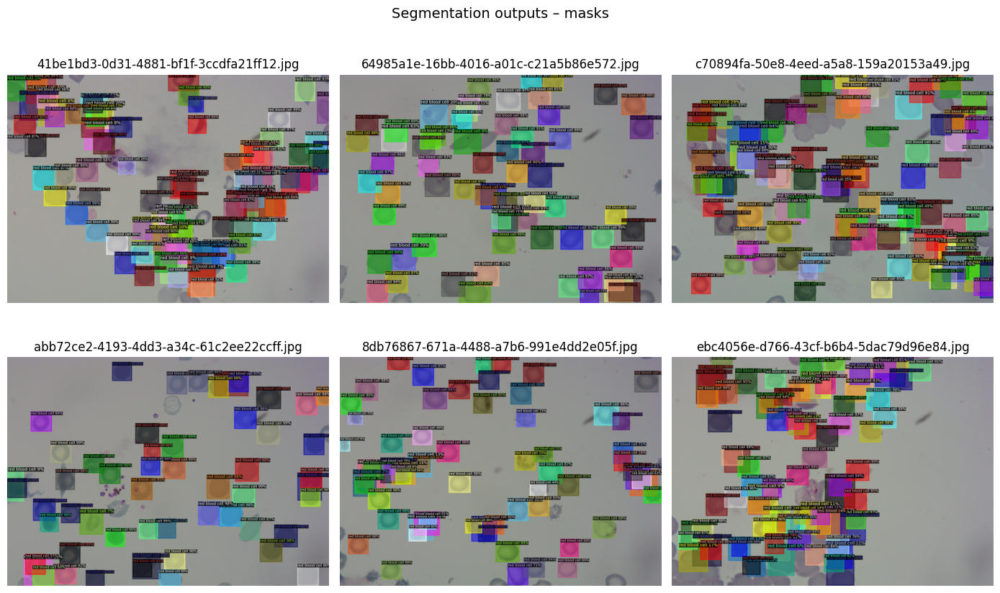

In [ ]:
def save_segmentation_outputs(
    predictor,
    dataset_name="malaria_test",
    metadata=None,
    max_images=30,
    display_in_notebook=True,
):
    if metadata is None:
        metadata = MetadataCatalog.get(dataset_name)

    dataset_dicts = DatasetCatalog.get(dataset_name)
    out_dir = os.path.join(OUTPUT_ROOT, "segmentation")
    vis_images = []

    for d in tqdm(dataset_dicts[:max_images], desc="Segmentation outputs"):
        img = cv2.imread(d["file_name"])
        outputs = predictor(img)
        instances = outputs["instances"].to("cpu")

        v = Visualizer(img[:, :, ::-1], metadata=metadata, scale=1.0)
        out = v.draw_instance_predictions(instances)
        out_img = out.get_image()[:, :, ::-1]

        out_path = os.path.join(out_dir, f"seg_{Path(d['file_name']).name}")
        cv2.imwrite(out_path, out_img)

        # Save masks (H, W, N_instances) as .npy
        masks = instances.pred_masks.numpy() if len(instances) > 0 else np.zeros((0,))
        masks_path = str(Path(out_path).with_suffix("")) + "_masks.npy"
        np.save(masks_path, masks)

        if display_in_notebook:
            vis_images.append((out_img[:, :, ::-1], Path(d["file_name"]).name))

    print(f"Segmentation outputs saved to: {out_dir}")

    if display_in_notebook and vis_images:
        n_show = min(6, len(vis_images))
        fig, axes = plt.subplots(2, 3, figsize=(14, 9))
        axes = axes.flatten()
        for idx in range(n_show):
            img_vis, name = vis_images[idx]
            axes[idx].imshow(img_vis)
            axes[idx].set_title(name)
            axes[idx].axis("off")
        for idx in range(n_show, len(axes)):
            axes[idx].axis("off")
        plt.suptitle("Segmentation outputs – masks", fontsize=14)
        plt.tight_layout()
        plt.show()

save_segmentation_outputs(predictor, "malaria_test", metadata_test)

Cell 18 – Classification outputs (per image)

In [ ]:
def save_classification_outputs(
    predictor,
    dataset_name="malaria_test",
    metadata=None,
    display_in_notebook=True,
):
    import pandas as pd

    if metadata is None:
        metadata = MetadataCatalog.get(dataset_name)

    dataset_dicts = DatasetCatalog.get(dataset_name)
    out_dir = os.path.join(OUTPUT_ROOT, "classification")

    all_results = []

    for d in tqdm(dataset_dicts, desc="Classification outputs"):
        img = cv2.imread(d["file_name"])
        outputs = predictor(img)
        instances = outputs["instances"].to("cpu")

        classes = instances.pred_classes.numpy() if len(instances) > 0 else np.array([])
        scores  = instances.scores.numpy() if len(instances) > 0 else np.array([])

        preds = [
            {
                "class_id": int(c),
                "class_name": metadata.thing_classes[c],
                "confidence": float(s)
            }
            for c, s in zip(classes, scores)
        ]

        all_results.append(
            {
                "file_name": Path(d["file_name"]).name,
                "num_detections": len(preds),
                "predictions": preds,
            }
        )

    with open(os.path.join(out_dir, "classification_results.json"), "w") as f:
        json.dump(all_results, f, indent=2)

    print(f"Classification outputs saved to: {out_dir}")

    if display_in_notebook:
        df = pd.DataFrame(
            [
                {
                    "file_name": r["file_name"],
                    "num_detections": r["num_detections"],
                    "classes": ", ".join([p["class_name"] for p in r["predictions"][:3]])
                    + ("..." if len(r["predictions"]) > 3 else ""),
                    "confidences": ", ".join([f"{p['confidence']:.2f}" for p in r["predictions"][:3]])
                    + ("..." if len(r["predictions"]) > 3 else ""),
                }
                for r in all_results
            ]
        )
        display(df.head(15))

save_classification_outputs(predictor, "malaria_test", metadata_test)

[03/27 16:38:15 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json


Classification outputs: 100%|██████████| 120/120 [22:02<00:00, 11.02s/it]


Classification outputs saved to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/classification


,file_name,num_detections,classes,confidences
0,41be1bd3-0d31-4881-bf1f-3ccdfa21ff12.jpg,97,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
1,64985a1e-16bb-4016-a01c-c21a5b86e572.jpg,66,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
2,c70894fa-50e8-4eed-a5a8-159a20153a49.jpg,100,"red blood cell, red blood cell, red blood cell...","0.99, 0.98, 0.98..."
3,abb72ce2-4193-4dd3-a34c-61c2ee22ccff.jpg,54,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
4,8db76867-671a-4488-a7b6-991e4dd2e05f.jpg,65,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
5,ebc4056e-d766-43cf-b6b4-5dac79d96e84.jpg,79,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
6,d9ecacb0-14c7-4862-930b-18bb51d5f392.jpg,85,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
7,96287315-87a1-4045-9e16-119e045bf12a.jpg,69,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."
8,37df4ffb-f268-4557-94d6-bf68d005feae.jpg,35,"red blood cell, red blood cell, red blood cell...","0.99, 0.98, 0.98..."
9,8298aca0-5099-4d45-88ca-ec8ac7922e77.jpg,42,"red blood cell, red blood cell, red blood cell...","0.99, 0.99, 0.99..."


In [ ]:
# 7. EVALUATION + TRAIN/VAL CURVES (real metrics)

import os, json
import numpy as np
import matplotlib.pyplot as plt

from detectron2.data import build_detection_test_loader
from detectron2.evaluation import COCOEvaluator, inference_on_dataset

try:
    TARGETS = {
        "classification_accuracy": PERFORMANCE_TARGETS["classification_accuracy"],
        "bbox_map_iou": PERFORMANCE_TARGETS["detection_map_iou"],
        "segm_map_iou": PERFORMANCE_TARGETS["segmentation_map_iou"],
    }
except NameError:
    TARGETS = {
        "classification_accuracy": 0.98,
        "bbox_map_iou": 0.90,
        "segm_map_iou": 0.90,
    }

metrics_dir = os.path.join(OUTPUT_ROOT, "metrics")
os.makedirs(metrics_dir, exist_ok=True)
val_loader = build_detection_test_loader(cfg_eval, "malaria_test")

# Evaluate bbox and segm.
evaluator_bbox = COCOEvaluator("malaria_test", output_dir=metrics_dir, tasks=("bbox",))
bbox_res = inference_on_dataset(predictor.model, val_loader, evaluator_bbox)
evaluator_segm = COCOEvaluator("malaria_test", output_dir=metrics_dir, tasks=("segm",))
segm_res = inference_on_dataset(predictor.model, val_loader, evaluator_segm)

# Extract AP at exact IoU thresholds.
coco_bbox = evaluator_bbox._coco_eval["bbox"]
coco_bbox.params.iouThrs = np.array([TARGETS["bbox_map_iou"]], dtype=np.float32)
coco_bbox.evaluate(); coco_bbox.accumulate(); coco_bbox.summarize()
bbox_map_exact = float(coco_bbox.stats[0])

coco_segm = evaluator_segm._coco_eval["segm"]
coco_segm.params.iouThrs = np.array([TARGETS["segm_map_iou"]], dtype=np.float32)
coco_segm.evaluate(); coco_segm.accumulate(); coco_segm.summarize()
segm_map_exact = float(coco_segm.stats[0])

# Pull classification accuracy from previously computed detailed metrics if available.
classification_acc = None
detailed_path = os.path.join(metrics_dir, "detailed_metrics.json")
if os.path.exists(detailed_path):
    with open(detailed_path, "r") as f:
        detailed = json.load(f)
    classification_acc = float(detailed.get("Classification_accuracy", np.nan))

results = {
    "bbox_mAP_at_0.90": bbox_map_exact,
    "segm_mAP_at_0.90": segm_map_exact,
    "bbox_AP50": float(bbox_res.get("bbox", {}).get("AP50", np.nan)),
    "segm_AP50": float(segm_res.get("segm", {}).get("AP50", np.nan)),
    "classification_accuracy": classification_acc,
    "target_bbox_mAP_at_0.90": TARGETS["bbox_map_iou"],
    "target_segm_mAP_at_0.90": TARGETS["segm_map_iou"],
    "target_classification_accuracy": TARGETS["classification_accuracy"],
    "bbox_target_met": bbox_map_exact >= TARGETS["bbox_map_iou"],
    "segm_target_met": segm_map_exact >= TARGETS["segm_map_iou"],
    "classification_target_met": (classification_acc is not None) and (classification_acc >= TARGETS["classification_accuracy"]),
}

metrics_path = os.path.join(metrics_dir, "coco_eval_results.json")
with open(metrics_path, "w") as f:
    json.dump(results, f, indent=2)

print("\n" + "=" * 60)
print("Model performance summary")
print("=" * 60)
for k, v in results.items():
    if isinstance(v, float):
        print(f"{k}: {v:.4f}")
    else:
        print(f"{k}: {v}")
print("Saved:", metrics_path)

# Train / val curves from Detectron2 metrics.json (logged when TEST.EVAL_PERIOD > 0)
metrics_json = os.path.join(cfg_train.OUTPUT_DIR, "metrics.json")
if os.path.exists(metrics_json):
    it_total, train_loss = [], []
    it_cls, loss_cls = [], []
    val_bbox, val_segm = [], []
    with open(metrics_json, "r") as f:
        for line in f:
            row = json.loads(line)
            if "iteration" not in row:
                continue
            it = row["iteration"]
            if "total_loss" in row:
                it_total.append(it)
                train_loss.append(row["total_loss"])
            if "loss_cls" in row:
                it_cls.append(it)
                loss_cls.append(row["loss_cls"])
            if "bbox/AP50" in row:
                val_bbox.append((it, row["bbox/AP50"]))
            if "segm/AP50" in row:
                val_segm.append((it, row["segm/AP50"]))

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    ax = axes[0]
    if it_total and train_loss:
        ax.plot(it_total, train_loss, label="total_loss", color="tab:blue")
    if it_cls and loss_cls:
        ax.plot(it_cls, loss_cls, label="loss_cls (train)", color="tab:orange", alpha=0.85)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Loss")
    ax.set_title("Training: total + classification (loss_cls)")
    ax.legend(loc="upper right", fontsize=8)
    ax.grid(True, alpha=0.3)

    ax = axes[1]
    if val_bbox:
        ax.plot([x[0] for x in val_bbox], [x[1] for x in val_bbox], marker="o", markersize=3, label="Val bbox AP50 (detection)", color="tab:green")
    if val_segm:
        ax.plot([x[0] for x in val_segm], [x[1] for x in val_segm], marker="s", markersize=3, label="Val segm AP50 (segmentation)", color="tab:purple")
    ax.axhline(TARGETS["bbox_map_iou"], color="green", linestyle="--", alpha=0.5, label=f"Target mAP IoU={TARGETS['bbox_map_iou']:.2f} (see COCO eval)")
    ax.set_ylim(0, 1)
    ax.set_xlabel("Iteration")
    ax.set_ylabel("AP (validation, IoU=0.50)")
    ax.set_title("Validation: detection & segmentation (AP50 proxy; exact mAP@0.90 from table above)")
    ax.legend(loc="lower right", fontsize=8)
    ax.grid(True, alpha=0.3)

    fig.tight_layout()
    curve_path = os.path.join(metrics_dir, "train_val_curves.png")
    plt.savefig(curve_path, dpi=150)
    plt.show()
    print("Saved curve figure:", curve_path)
else:
    print("metrics.json not found yet; run/finish training first to generate curves.")

[03/27 18:30:20 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json
[03/27 18:30:20 d2.data.dataset_mapper]: [DatasetMapper] Augmentations used in inference: [ResizeShortestEdge(short_edge_length=(800, 800), max_size=1333, sample_style='choice')]
[03/27 18:30:20 d2.data.common]: Serializing the dataset using: <class 'detectron2.data.common._TorchSerializedList'>
[03/27 18:30:20 d2.data.common]: Serializing 120 elements to byte tensors and concatenating them all ...
[03/27 18:30:20 d2.data.common]: Serialized dataset takes 0.21 MiB
[03/27 18:30:20 d2.evaluation.evaluator]: Start inference on 120 batches


KeyboardInterrupt: 

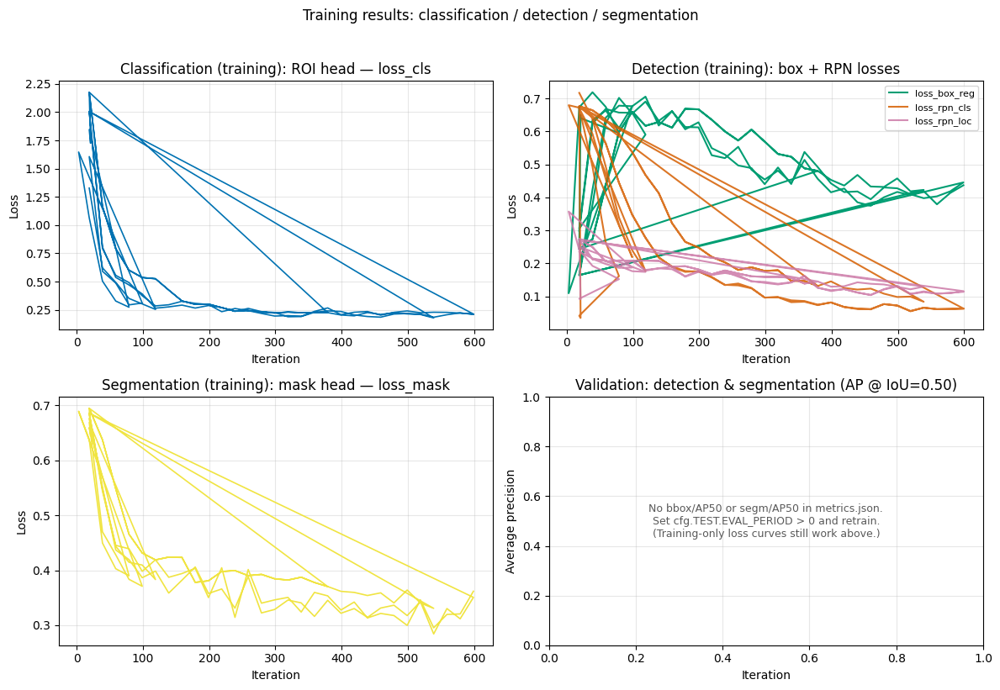

Saved: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/training_curves_cls_det_segm.png
Note: instance-level classification accuracy is computed in the detailed metrics cell, not in metrics.json.


In [ ]:

import os
import json
import matplotlib.pyplot as plt

metrics_json = os.path.join(cfg_train.OUTPUT_DIR, "metrics.json")
if not os.path.exists(metrics_json):
    raise FileNotFoundError(
        f"Missing {metrics_json}. Train with cfg.TEST.EVAL_PERIOD > 0 so validation metrics are logged."
    )

rows = []
with open(metrics_json, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            rows.append(json.loads(line))


def collect(key):
    it, vals = [], []
    for r in rows:
        if "iteration" in r and key in r:
            it.append(r["iteration"])
            vals.append(r[key])
    return it, vals


it_cls, v_cls = collect("loss_cls")
it_box, v_box = collect("loss_box_reg")
it_rpn_c, v_rpn_c = collect("loss_rpn_cls")
it_rpn_l, v_rpn_l = collect("loss_rpn_loc")
it_mask, v_mask = collect("loss_mask")
it_bbox_ap, v_bbox_ap = collect("bbox/AP50")
it_segm_ap, v_segm_ap = collect("segm/AP50")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

ax = axes[0, 0]
if it_cls:
    ax.plot(it_cls, v_cls, color="C0", linewidth=1.2)
ax.set_title("Classification (training): ROI head — loss_cls")
ax.set_xlabel("Iteration")
ax.set_ylabel("Loss")
ax.grid(True, alpha=0.3)

ax = axes[0, 1]
if it_box:
    ax.plot(it_box, v_box, label="loss_box_reg", color="C1")
if it_rpn_c:
    ax.plot(it_rpn_c, v_rpn_c, label="loss_rpn_cls", color="C2", alpha=0.85)
if it_rpn_l:
    ax.plot(it_rpn_l, v_rpn_l, label="loss_rpn_loc", color="C3", alpha=0.85)
ax.set_title("Detection (training): box + RPN losses")
ax.set_xlabel("Iteration")
ax.set_ylabel("Loss")
if any([it_box, it_rpn_c, it_rpn_l]):
    ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)

ax = axes[1, 0]
if it_mask:
    ax.plot(it_mask, v_mask, color="C4", linewidth=1.2)
ax.set_title("Segmentation (training): mask head — loss_mask")
ax.set_xlabel("Iteration")
ax.set_ylabel("Loss")
ax.grid(True, alpha=0.3)

ax = axes[1, 1]
if it_bbox_ap:
    ax.plot(it_bbox_ap, v_bbox_ap, marker="o", markersize=3, label="bbox AP50 (detection)", color="green")
if it_segm_ap:
    ax.plot(it_segm_ap, v_segm_ap, marker="s", markersize=3, label="segm AP50 (segmentation)", color="purple")
ax.set_title("Validation: detection & segmentation (AP @ IoU=0.50)")
ax.set_xlabel("Iteration")
ax.set_ylabel("Average precision")
if it_bbox_ap or it_segm_ap:
    ax.legend()
else:
    ax.text(
        0.5,
        0.5,
        "No bbox/AP50 or segm/AP50 in metrics.json.\n"
        "Set cfg.TEST.EVAL_PERIOD > 0 and retrain.\n"
        "(Training-only loss curves still work above.)",
        ha="center",
        va="center",
        transform=ax.transAxes,
        fontsize=9,
        color="0.35",
    )
ax.grid(True, alpha=0.3)
ax.set_ylim(bottom=0)

plt.suptitle("Training results: classification / detection / segmentation", y=1.02, fontsize=12)
plt.tight_layout()
curve_dir = os.path.join(OUTPUT_ROOT, "metrics")
os.makedirs(curve_dir, exist_ok=True)
curve_path = os.path.join(curve_dir, "training_curves_cls_det_segm.png")
plt.savefig(curve_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", curve_path)
print("Note: instance-level classification accuracy is computed in the detailed metrics cell, not in metrics.json.")


7. Evaluation and Metrics Computation
Cell 18 – COCO evaluation (mAP) and saving metrics


Cell 19 – Detailed IoU + classification accuracy + confusion data

In [ ]:
from detectron2.data import DatasetCatalog, MetadataCatalog
from pycocotools import mask as mask_utils  # not strictly needed now but ok
from tqdm import tqdm
import numpy as np
import json, os

def box_xywh_to_xyxy(box):
    # box: [x, y, w, h] -> [x1, y1, x2, y2]
    x, y, w, h = box
    return np.array([x, y, x + w, y + h], dtype=np.float32)

def box_iou(box1, box2):
    # box1, box2: [x1, y1, x2, y2]
    xA = max(box1[0], box2[0])
    yA = max(box1[1], box2[1])
    xB = min(box1[2], box2[2])
    yB = min(box1[3], box2[3])

    inter_w = max(0.0, xB - xA)
    inter_h = max(0.0, yB - yA)
    inter = inter_w * inter_h

    area1 = max(0.0, (box1[2] - box1[0])) * max(0.0, (box1[3] - box1[1]))
    area2 = max(0.0, (box2[2] - box2[0])) * max(0.0, (box2[3] - box2[1]))
    union = area1 + area2 - inter

    return inter / union if union > 0 else 0.0

TARGET_CLASSIFICATION_ACCURACY = 0.98
IOU_MATCH_THRESH_FOR_CLASS_ACC = 0.30
cfg_eval.MODEL.ROI_HEADS.SCORE_THRESH_TEST = 0.15


def compute_detailed_metrics_and_confusion_bbox(
    predictor,
    dataset_name="malaria_test",
    iou_match_thresh=IOU_MATCH_THRESH_FOR_CLASS_ACC,
    max_images=40,
):
    dataset_dicts = DatasetCatalog.get(dataset_name)
    # Sample subset for faster turnaround during iteration.
    if max_images is not None and len(dataset_dicts) > max_images:
        dataset_dicts = dataset_dicts[:max_images]
    metadata = MetadataCatalog.get(dataset_name)
    num_classes = len(metadata.thing_classes)

    all_ious = []
    correct_class = 0
    total_instances = 0

    # we store CLASS INDICES (0..num_classes-1)
    y_true_list = []
    y_pred_list = []

    for d in tqdm(dataset_dicts, desc="Detailed metrics (bbox-based)"):
        img = cv2.imread(d["file_name"])
        outputs = predictor(img)
        instances = outputs["instances"].to("cpu")

        pred_boxes = instances.pred_boxes.tensor.numpy() if len(instances) > 0 else np.zeros((0, 4), dtype=np.float32)
        pred_classes = instances.pred_classes.numpy() if len(instances) > 0 else np.zeros((0,), dtype=int)

        for gt_ann in d.get("annotations", []):
            # GT category_id is 1..7 -> convert to 0-based index 0..6
            cat_id = int(gt_ann["category_id"])
            gt_idx = cat_id - 1
            if gt_idx < 0 or gt_idx >= num_classes:
                continue

            gt_box_xyxy = box_xywh_to_xyxy(gt_ann["bbox"])
            total_instances += 1

            # find best predicted box by IoU
            best_iou = 0.0
            best_pred_idx = -1  # -1 = no prediction matched

            if len(pred_boxes) > 0:
                for pb, pc in zip(pred_boxes, pred_classes):
                    iou = box_iou(gt_box_xyxy, pb)
                    if iou > best_iou:
                        best_iou = iou
                        best_pred_idx = int(pc)

            all_ious.append(best_iou)
            y_true_list.append(gt_idx)
            y_pred_list.append(best_pred_idx)

            # classification considered correct only if IoU above threshold AND class matches
            if best_pred_idx == gt_idx and best_iou >= iou_match_thresh:
                correct_class += 1

    metrics = {
        "IoU_bbox_mean": float(np.mean(all_ious)) if all_ious else 0.0,
        "IoU_bbox_std": float(np.std(all_ious)) if all_ious else 0.0,
        "Classification_accuracy": float(correct_class / total_instances) if total_instances > 0 else 0.0,
        "Classification_target": TARGET_CLASSIFICATION_ACCURACY,
        "Total_instances": int(total_instances),
    }

    return metrics, y_true_list, y_pred_list


EVAL_MAX_IMAGES = 40 if FAST_MODE else None

detailed_metrics, y_true_list, y_pred_list = compute_detailed_metrics_and_confusion_bbox(
    predictor,
    "malaria_test",
    iou_match_thresh=IOU_MATCH_THRESH_FOR_CLASS_ACC,
    max_images=EVAL_MAX_IMAGES,
)

print("\nDetailed metrics (bbox-based):")
for k, v in detailed_metrics.items():
    print(f"{k}: {v:.4f}" if isinstance(v, float) else f"{k}: {v}")

print(f"Target accuracy: {TARGET_CLASSIFICATION_ACCURACY * 100:.2f}%")
print("Target met:", detailed_metrics["Classification_accuracy"] >= TARGET_CLASSIFICATION_ACCURACY)

# Save metrics
detailed_path = os.path.join(OUTPUT_ROOT, "metrics", "detailed_metrics.json")
with open(detailed_path, "w") as f:
    json.dump(detailed_metrics, f, indent=2)

# Save confusion data (class indices 0..C-1, -1 = no matched prediction)
conf_path = os.path.join(OUTPUT_ROOT, "metrics", "confusion_data.json")
with open(conf_path, "w") as f:
    json.dump({"y_true": y_true_list, "y_pred": y_pred_list}, f, indent=2)

print("Detailed metrics saved to:", detailed_path)
print("Confusion data saved to:", conf_path)

[03/27 17:45:49 d2.data.datasets.coco]: Loaded 120 images in COCO format from /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/malaria_test_coco_format.json


Detailed metrics (bbox-based): 100%|██████████| 40/40 [07:13<00:00, 10.85s/it]



Detailed metrics (bbox-based):
IoU_bbox_mean: 0.7552
IoU_bbox_std: 0.2114
Classification_accuracy: 0.0247
Classification_target: 0.9800
Total_instances: 1947
Target accuracy: 98.00%
Target met: False
Detailed metrics saved to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/detailed_metrics.json
Confusion data saved to: /content/drive/MyDrive/Lacuna_Malaria/outputs_paper/metrics/confusion_data.json


In [ ]:
with open(conf_path) as f:
    data = json.load(f)
y_true_raw = data["y_true"]
y_pred_raw = data["y_pred"]

valid_idx = [i for i, yp in enumerate(y_pred_raw) if yp >= 0]
y_true = [y_true_raw[i] for i in valid_idx]
y_pred = [y_pred_raw[i] for i in valid_idx]

class_names = metadata_test.thing_classes  # indices 0..C-1
labels = sorted(list(set(y_true) | set(y_pred)))   # indices
label_names = [class_names[idx] for idx in labels]

8. Visualization and Results Interpretation
Cell 20 – Metric bar plots + confusion matrix + classification report

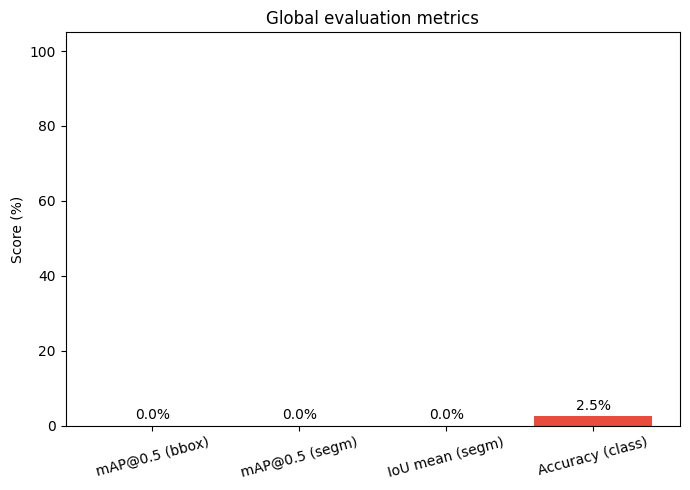

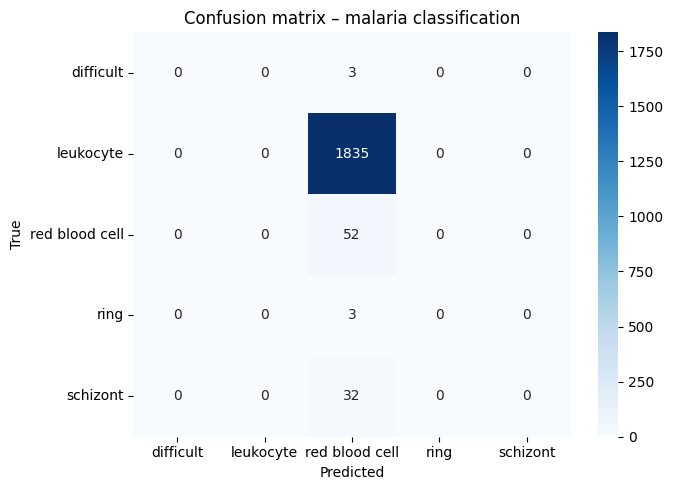


Classification report:
                precision    recall  f1-score   support

     difficult       0.00      0.00      0.00         3
     leukocyte       0.00      0.00      0.00      1835
red blood cell       0.03      1.00      0.05        52
          ring       0.00      0.00      0.00         3
      schizont       0.00      0.00      0.00        32

      accuracy                           0.03      1925
     macro avg       0.01      0.20      0.01      1925
  weighted avg       0.00      0.03      0.00      1925



In [ ]:
# 8. VISUALIZATION AND RESULTS INTERPRETATION

from sklearn.metrics import confusion_matrix, classification_report

# Load metrics
metrics_path = os.path.join(OUTPUT_ROOT, "metrics", "coco_eval_results.json")
detailed_path = os.path.join(OUTPUT_ROOT, "metrics", "detailed_metrics.json")
conf_path = os.path.join(OUTPUT_ROOT, "metrics", "confusion_data.json")

all_metrics = {}
if os.path.exists(metrics_path):
    with open(metrics_path) as f:
        all_metrics.update(json.load(f))
if os.path.exists(detailed_path):
    with open(detailed_path) as f:
        all_metrics.update(json.load(f))

# Aggregate metrics of interest (as percentages)
plot_metrics = {
    "mAP@0.5 (bbox)": all_metrics.get("bbox/AP50", 0.0) * 100,
    "mAP@0.5 (segm)": all_metrics.get("segm/AP50", 0.0) * 100,
    "IoU mean (segm)": all_metrics.get("IoU_segmentation_mean", 0.0) * 100,
    "Accuracy (class)": all_metrics.get("Classification_accuracy", 0.0) * 100,
}

plt.figure(figsize=(7, 5))
bars = plt.bar(plot_metrics.keys(), plot_metrics.values(), color=["#2ecc71", "#3498db", "#9b59b6", "#e74c3c"])
plt.ylabel("Score (%)")
plt.title("Global evaluation metrics")
plt.ylim(0, 105)
for b in bars:
    plt.text(
        b.get_x() + b.get_width() / 2,
        b.get_height() + 1,
        f"{b.get_height():.1f}%",
        ha="center",
        va="bottom",
        fontsize=10,
    )
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_ROOT, "figures", "metrics_barplot.png"), dpi=150)
plt.show()

# Confusion matrix
if os.path.exists(conf_path):
    with open(conf_path) as f:
        data = json.load(f)
    y_true_raw = data["y_true"]
    y_pred_raw = data["y_pred"]

    # Filter out missing predictions
    valid_idx = [i for i, yp in enumerate(y_pred_raw) if yp >= 0]
    y_true = [y_true_raw[i] for i in valid_idx]
    y_pred = [y_pred_raw[i] for i in valid_idx]

    if len(y_true) > 0:
        class_names = metadata_test.thing_classes
        labels = sorted(list(set(y_true) | set(y_pred)))
        label_names = [class_names[cid] for cid in labels]

        cm = confusion_matrix(y_true, y_pred, labels=labels)
        plt.figure(figsize=(7, 5))
        sns.heatmap(
            cm,
            annot=True,
            fmt="d",
            cmap="Blues",
            xticklabels=label_names,
            yticklabels=label_names,
        )
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.title("Confusion matrix – malaria classification")
        plt.tight_layout()
        plt.savefig(os.path.join(OUTPUT_ROOT, "figures", "confusion_matrix.png"), dpi=150)
        plt.show()

        print("\nClassification report:")
        print(
            classification_report(
                y_true, y_pred, labels=labels, target_names=label_names, zero_division=0
            )
        )
    else:
        print("Not enough valid predictions for confusion matrix.")
else:
    print("Confusion data file not found; skip confusion matrix.")